# 02 · Where carts leak, and which gaps survive scrutiny
Cart → purchase conversion (strict, same session) and the value of carts left behind, by top-level
category, within-category price quartile and first-time vs returning buyer. Every rate gap is
stress-tested twice: a Simpson's paradox check (category mix) and a cart-logging bound.

In [1]:
import json, os
from itertools import combinations
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = os.environ.get("FUNNEL_DB", ROOT / "data/processed/funnel.duckdb")
FIG = ROOT / "outputs/figures"
RESULTS = ROOT / "outputs/results.json"
con = duckdb.connect(str(DB), read_only=True)
results = json.loads(RESULTS.read_text())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
TIERS = {1: "Q1 budget", 2: "Q2", 3: "Q3", 4: "Q4 premium"}
SCALE = 10  # 10% user sample -> full store
MIN_CARTS = 50

## 1 · Where the abandoned value sits

In [2]:
seg = con.sql("SELECT * FROM segment_funnel").df()
seg["tier"] = seg.price_tier.map(TIERS)
seg.to_csv(ROOT / "outputs/segment_funnel.csv", index=False)  # Tableau source
overall_rate = seg.purchased.sum() / seg.carted.sum()
results["overall_cart_to_purchase"] = round(overall_rate, 4)
results["sample_abandoned_value"] = round(seg.abandoned_value.sum(), 0)
print(f"Overall strict cart→purchase: {overall_rate:.1%}; abandoned cart value: "
      f"${seg.abandoned_value.sum():,.0f} in the sample, ~${seg.abandoned_value.sum() * SCALE / 1e6:,.0f}M store-wide")

Overall strict cart→purchase: 50.5%; abandoned cart value: $9,864,714 in the sample, ~$99M store-wide


In [3]:
cats = seg.groupby("category").carted.sum().loc[lambda s: s >= 4 * MIN_CARTS].sort_values(ascending=False).index
cells = seg[seg.category.isin(cats) & (seg.carted >= MIN_CARTS)].copy()
cells["abandoned"] = cells.carted - cells.purchased
cells["avg_cart_price"] = cells.abandoned_value / cells.abandoned
cells["value_share"] = cells.abandoned_value / seg.abandoned_value.sum()
ranked = cells.sort_values("abandoned_value", ascending=False)
top = ranked.iloc[0]
results["top_leak"] = {"category": top.category, "tier": top.tier, "carted": int(top.carted),
                       "cart_to_purchase": round(top.cart_to_purchase, 4),
                       "abandoned_value_sample": round(top.abandoned_value, 0),
                       "value_share": round(top.value_share, 4),
                       "avg_abandoned_cart_value": round(top.avg_cart_price, 2)}
cat_share = seg.groupby("category").abandoned_value.sum().div(seg.abandoned_value.sum()).sort_values(ascending=False)
results["abandoned_value_share_by_category"] = cat_share.round(4).head(5).to_dict()
print(cat_share.head(5).round(3))
ranked[["category", "tier", "carted", "cart_to_purchase", "avg_cart_price", "abandoned_value", "value_share"]].head(8).round(3)

category
electronics    0.826
appliances     0.070
unknown        0.046
computers      0.045
auto           0.004
Name: abandoned_value, dtype: float64


,category,tier,carted,cart_to_purchase,avg_cart_price,abandoned_value,value_share
11,electronics,Q4 premium,16208,0.534,795.087,6007675.871,0.609
20,electronics,Q3,16974,0.538,215.900,1694597.399,0.172
41,electronics,Q2,8308,0.568,118.985,426679.362,0.043
22,computers,Q4 premium,700,0.489,851.580,304865.530,0.031
32,appliances,Q4 premium,952,0.395,528.912,304653.380,0.031
39,unknown,Q4 premium,1303,0.394,358.972,283229.060,0.029
26,appliances,Q3,1812,0.417,259.228,273744.930,0.028
13,computers,Q3,701,0.445,312.857,121701.240,0.012


Ranking by abandoned dollars mostly ranks by price: expensive carts lose more dollars at any
conversion rate. A fairer ranking is **excess loss**: the value lost because a cell converts below
the best tier of its own category.

In [4]:
best = cells.groupby("category").cart_to_purchase.transform("max")
cells["excess_loss_full_store"] = (best - cells.cart_to_purchase) * cells.carted * cells.avg_cart_price * SCALE
excess = cells.sort_values("excess_loss_full_store", ascending=False)
results["excess_loss_top"] = excess[["category", "tier", "cart_to_purchase", "excess_loss_full_store"]].head(3).round(4).to_dict("records")
excess[["category", "tier", "carted", "cart_to_purchase", "excess_loss_full_store"]].head(6).round(3)

,category,tier,carted,cart_to_purchase,excess_loss_full_store
11,electronics,Q4 premium,16208,0.534,4453328.259
20,electronics,Q3,16974,0.538,1128023.874
32,appliances,Q4 premium,952,0.395,509828.105
26,appliances,Q3,1812,0.417,371039.378
13,computers,Q3,701,0.445,95385.526
53,electronics,Q1 budget,1402,0.395,66127.432


## 2 · Is the price-tier gap real?
**Check A, Simpson's paradox.** Pooled tier rates mix categories with very different baselines. The
mix-adjusted rate holds the category mix fixed (each category weighted by its share of carts).

In [5]:
by_ct = seg[seg.category.isin(cats)]
pooled = by_ct.groupby("price_tier")[["carted", "purchased"]].sum()
pooled["pooled_rate"] = pooled.purchased / pooled.carted
weights = by_ct.groupby("category").carted.sum() / by_ct.carted.sum()
within = by_ct.assign(rate=by_ct.purchased / by_ct.carted).pivot(index="category", columns="price_tier", values="rate")
pooled["mix_adjusted_rate"] = [np.nansum(within[t] * weights) / weights[within[t].notna()].sum() for t in pooled.index]
pooled.index = pooled.index.map(TIERS)
reversals = [f"{b} vs {a}" for a, b in combinations(pooled.index, 2)
             if np.sign(pooled.pooled_rate[b] - pooled.pooled_rate[a]) != np.sign(pooled.mix_adjusted_rate[b] - pooled.mix_adjusted_rate[a])]
results["simpson"] = {"found": bool(reversals), "reversed_pairs": reversals,
                      "pooled": pooled.pooled_rate.round(4).to_dict(),
                      "mix_adjusted": pooled.mix_adjusted_rate.round(4).to_dict()}
print(f"Tier pairs whose ordering flips after mix adjustment: {reversals or 'none'}")
pooled.round(4)

Tier pairs whose ordering flips after mix adjustment: ['Q4 premium vs Q2', 'Q4 premium vs Q3']


,carted,purchased,pooled_rate,mix_adjusted_rate
price_tier,,,,
Q1 budget,3972,1620,0.4079,0.3938
Q2,14096,7228,0.5128,0.5330
Q3,21674,11096,0.5119,0.5051
Q4 premium,19222,9908,0.5155,0.4993


**Check B, cart-logging bound.** Many purchases have no earlier cart in the session (notebook 01).
Strict rates assume those shoppers never carted. The opposite extreme assumes each of them had an
unlogged cart: `(purchased + no-cart purchases) / (carted + no-cart purchases)`. The truth lies
between the two. A gap that holds at both ends does not depend on how carts were logged.

In [6]:
def bounded(group_cols, where="TRUE"):
    cols = ", ".join(group_cols)
    return con.sql(f"""
        SELECT {cols}, sum(carted::INT) AS carted, sum(purchase_skipped_step::INT) AS no_cart_purchases,
            sum(purchased::INT) / sum(carted::INT) AS strict_rate,
            (sum(purchased::INT) + sum(purchase_skipped_step::INT))
                / (sum(carted::INT) + sum(purchase_skipped_step::INT)) AS bound_rate
        FROM funnel_sp WHERE {where} GROUP BY ALL ORDER BY ALL""").df()

tier_b = bounded(["price_tier"], f"category = '{top.category}'")
tier_b["tier"] = tier_b.price_tier.map(TIERS)
q2, q4 = tier_b.set_index("price_tier").loc[2], tier_b.set_index("price_tier").loc[4]
results["tier_robustness"] = {"category": top.category,
                              "q4_minus_q2_strict_pp": round(100 * (q4.strict_rate - q2.strict_rate), 2),
                              "q4_minus_q2_bound_pp": round(100 * (q4.bound_rate - q2.bound_rate), 2),
                              "no_cart_share_q2": round(q2.no_cart_purchases / (q2.no_cart_purchases + q2.carted * q2.strict_rate), 4),
                              "no_cart_share_q4": round(q4.no_cart_purchases / (q4.no_cart_purchases + q4.carted * q4.strict_rate), 4)}
print(results["tier_robustness"])
tier_b.round(4)

{'category': 'electronics', 'q4_minus_q2_strict_pp': np.float64(-3.46), 'q4_minus_q2_bound_pp': np.float64(0.74), 'no_cart_share_q2': np.float64(0.3252), 'no_cart_share_q4': np.float64(0.4325)}


,price_tier,carted,no_cart_purchases,strict_rate,bound_rate,tier
0,1,1402.0,1195.0,0.3951,0.6735,Q1 budget
1,2,8308.0,2276.0,0.5684,0.6612,Q2
2,3,16974.0,5223.0,0.5376,0.6464,Q3
3,4,16208.0,6594.0,0.5338,0.6686,Q4 premium


## 3 · First-time vs returning buyers
"Returning" means the user made a purchase earlier in October than this session-product's first
event. Buyers from before October count as first-time, which biases the gap toward zero.

In [7]:
cust = bounded(["category = 'electronics' AS electronics", "is_returning"])
cust_tier = bounded(["price_tier", "is_returning"], "category = 'electronics'")
e = cust[cust.electronics].set_index("is_returning")
gap_strict = e.strict_rate[True] - e.strict_rate[False]
gap_bound = e.bound_rate[True] - e.bound_rate[False]
tier_gaps = cust_tier.pivot(index="price_tier", columns="is_returning", values="strict_rate")
results["customer_split"] = {
    "category": "electronics",
    "first_time_share_of_carts": round(e.carted[False] / e.carted.sum(), 4),
    "strict": {"first_time": round(e.strict_rate[False], 4), "returning": round(e.strict_rate[True], 4)},
    "bound": {"first_time": round(e.bound_rate[False], 4), "returning": round(e.bound_rate[True], 4)},
    "gap_strict_pp": round(100 * gap_strict, 2), "gap_bound_pp": round(100 * gap_bound, 2),
    "gap_by_tier_pp": (100 * (tier_gaps[True] - tier_gaps[False])).round(1).rename(TIERS).to_dict(),
    "non_electronics_gap_strict_pp": round(100 * (cust[~cust.electronics].set_index("is_returning").strict_rate.diff().iloc[-1]), 2),
}
print(json.dumps(results["customer_split"], indent=1))
cust.round(4)

{
 "category": "electronics",
 "first_time_share_of_carts": 0.6392,
 "strict": {
  "first_time": 0.4253,
  "returning": 0.7362
 },
 "bound": {
  "first_time": 0.5478,
  "returning": 0.825
 },
 "gap_strict_pp": 31.08,
 "gap_bound_pp": 27.72,
 "gap_by_tier_pp": {
  "Q1 budget": 26.4,
  "Q2": 29.3,
  "Q3": 30.9,
  "Q4 premium": 32.4
 },
 "non_electronics_gap_strict_pp": 28.36
}


,electronics,is_returning,carted,no_cart_purchases,strict_rate,bound_rate
0,False,False,11576.0,12695.0,0.3354,0.6830
1,False,True,4961.0,10028.0,0.6190,0.8739
2,True,False,27417.0,7429.0,0.4253,0.5478
3,True,True,15475.0,7859.0,0.7362,0.8250


## Tableau export
One row per category × price tier × buyer type, sample counts (multiply by 10 for the full store).

In [8]:
tableau = con.sql("""
    SELECT category, price_tier, CASE WHEN is_returning THEN 'Returning' ELSE 'First-time' END AS buyer_type,
        count(*) FILTER (WHERE carted) AS carted,
        count(*) FILTER (WHERE purchased) AS purchased,
        count(*) FILTER (WHERE purchase_skipped_step) AS no_cart_purchases,
        round(sum(cart_price) FILTER (WHERE carted AND NOT purchased), 2) AS abandoned_value,
        round(sum(purchase_price) FILTER (WHERE purchased), 2) AS purchased_value
    FROM funnel_sp GROUP BY ALL ORDER BY ALL""").df()
tableau["tier"] = tableau.price_tier.map(TIERS)
tableau.to_csv(ROOT / "outputs/tableau_funnel.csv", index=False)
tableau.head()

,category,price_tier,buyer_type,carted,purchased,no_cart_purchases,abandoned_value,purchased_value,tier
0,accessories,1,First-time,15,4,25,127.57,43.47,Q1 budget
1,accessories,1,Returning,12,5,17,80.25,60.85,Q1 budget
2,accessories,2,First-time,7,3,19,183.84,114.33,Q2
3,accessories,2,Returning,4,1,26,109.24,36.01,Q2
4,accessories,3,First-time,1,0,13,59.18,NaN,Q3


## Dashboard figure

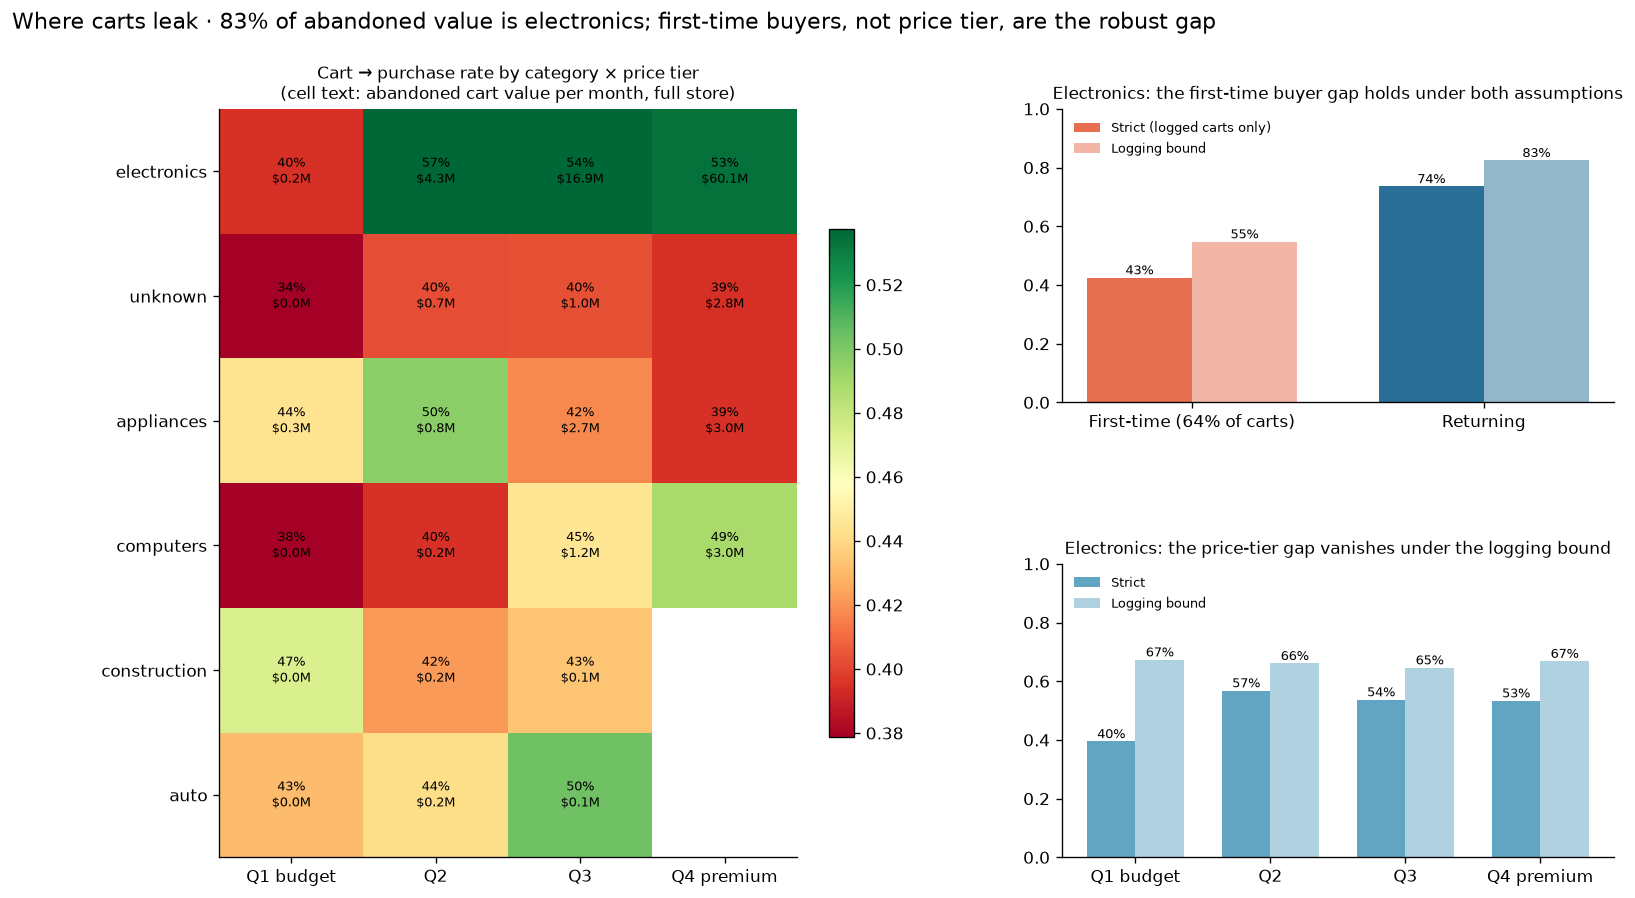

In [9]:
heat = cells.pivot(index="category", columns="tier", values="cart_to_purchase").reindex(cats)
heat = heat[[t for t in TIERS.values() if t in heat.columns]]
lost = cells.pivot(index="category", columns="tier", values="abandoned_value").reindex(cats)[heat.columns] * SCALE

fig = plt.figure(figsize=(15, 0.6 * len(cats) + 4.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], hspace=0.55, wspace=0.35)
a1, a2, a3 = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
im = a1.imshow(heat.values, cmap="RdYlGn", vmin=np.nanpercentile(heat.values, 5), vmax=np.nanpercentile(heat.values, 95), aspect="auto")
a1.set_xticks(range(heat.shape[1]), heat.columns); a1.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if not np.isnan(heat.values[i, j]):
            a1.text(j, i, f"{heat.values[i, j]:.0%}\n${lost.values[i, j] / 1e6:.1f}M", ha="center", va="center", fontsize=8)
a1.set_title("Cart → purchase rate by category × price tier\n(cell text: abandoned cart value per month, full store)", fontsize=10)
fig.colorbar(im, ax=a1, fraction=0.04)

x = np.arange(2); w = 0.36
for k, (col, label, alpha) in enumerate([("strict_rate", "Strict (logged carts only)", 1.0), ("bound_rate", "Logging bound", 0.5)]):
    vals = [e[col][False], e[col][True]]
    bars = a2.bar(x + (k - 0.5) * w, vals, w, color=["#e76f51", "#2a6f97"], alpha=alpha, label=label)
    a2.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8)
a2.set_xticks(x, [f"First-time ({e.carted[False] / e.carted.sum():.0%} of carts)", "Returning"])
a2.set_ylim(0, 1); a2.set_title("Electronics: the first-time buyer gap holds under both assumptions", fontsize=10)
a2.legend(fontsize=8, loc="upper left", frameon=False)

for k, (col, label, alpha) in enumerate([("strict_rate", "Strict", 1.0), ("bound_rate", "Logging bound", 0.5)]):
    vals = tier_b[col].values
    bars = a3.bar(np.arange(len(tier_b)) + (k - 0.5) * w, vals, w, color="#61a5c2", alpha=alpha, label=label)
    a3.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8)
a3.set_xticks(range(len(tier_b)), tier_b.tier); a3.set_ylim(0, 1)
a3.set_title("Electronics: the price-tier gap vanishes under the logging bound", fontsize=10)
a3.legend(fontsize=8, loc="upper left", frameon=False)
fig.suptitle(f"Where carts leak · {cat_share.iloc[0]:.0%} of abandoned value is {cat_share.index[0]}; "
             f"first-time buyers, not price tier, are the robust gap", fontsize=13, x=0.01, ha="left")
fig.savefig(FIG / "dashboard_1.png", bbox_inches="tight"); plt.show()

In [10]:
RESULTS.write_text(json.dumps(results, indent=2, default=float))

9432